Viewing Study ID: 1.2.826.0.1.3680043.8.498.10843463954622076609489312662891432839
Found 5 series folders in this study.
Loaded Series Shape: (186, 640, 640) -> (186 Slices, 640x640 pixels)


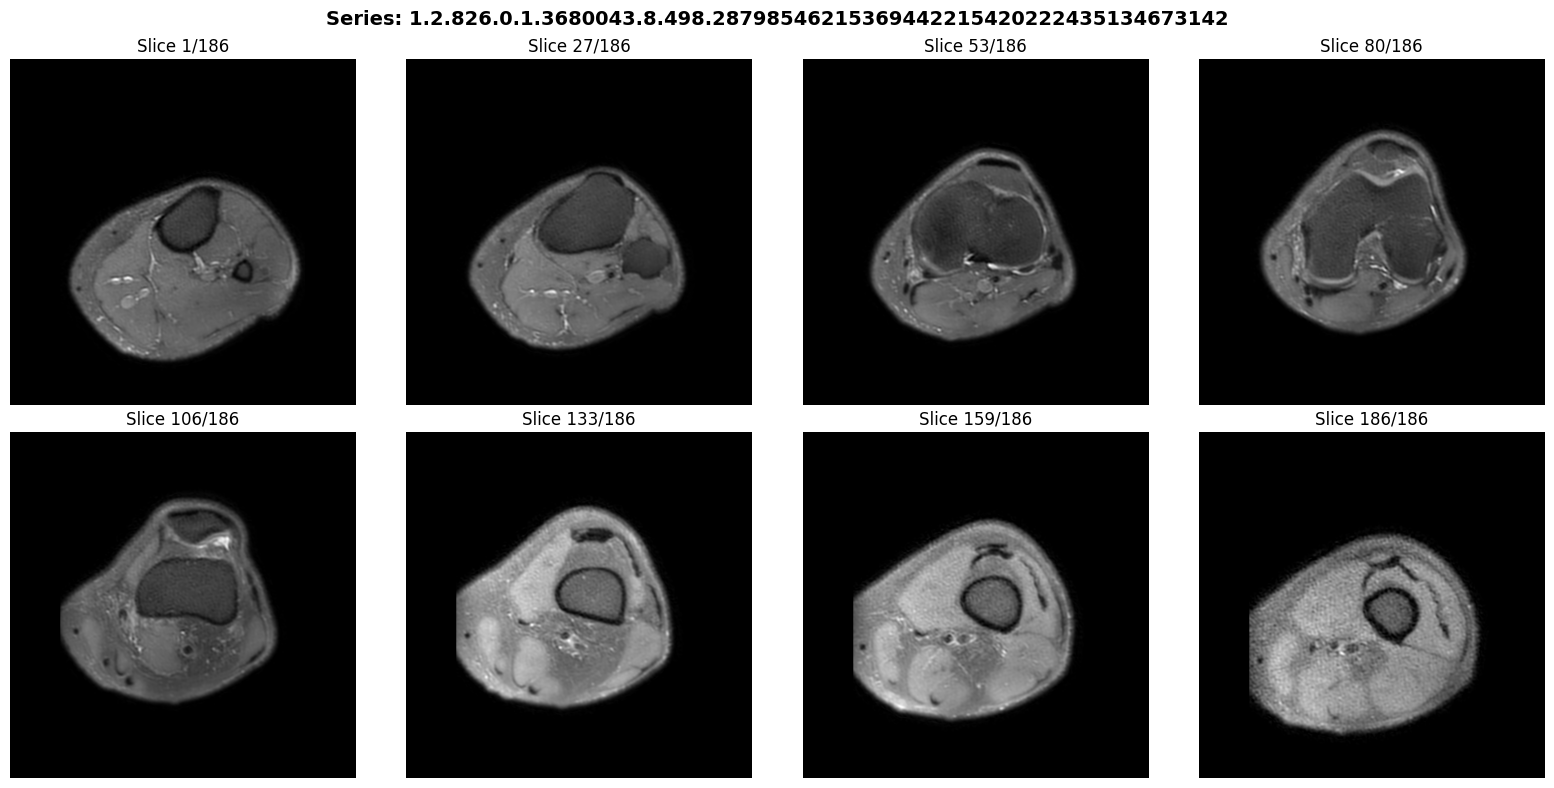

In [1]:
import pathlib
import pydicom
import numpy as np
import matplotlib.pyplot as plt

# 1. Point to your train_series directory
# (Adjust this path if your Kaggle dataset folder name is slightly different)
TRAIN_SERIES_DIR = pathlib.Path("/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series")

# Grab the first available study folder
study_folders = [f for f in TRAIN_SERIES_DIR.iterdir() if f.is_dir()]
sample_study = study_folders[0]
print(f"Viewing Study ID: {sample_study.name}")

# List all series (camera angles/sequences) inside this study
series_folders = [f for f in sample_study.iterdir() if f.is_dir()]
print(f"Found {len(series_folders)} series folders in this study.")


# 2. Helper function to load and sort DICOM slices into a 3D NumPy array
def load_series(series_path):
    dcm_files = list(series_path.glob("*.dcm"))

    # Read each DICOM file
    slices = [pydicom.dcmread(f) for f in dcm_files]

    # Sort slices in anatomical order using InstanceNumber or spatial position
    slices.sort(key=lambda s: int(s.InstanceNumber) if 'InstanceNumber' in s else float(s.ImagePositionPatient[2]))

    # Extract the raw 2D pixel array from each slice
    images = np.array([s.pixel_array for s in slices])
    return images, slices[0]  # Return images volume + first slice header info


# 3. Plot evenly-spaced slices from the FIRST series
series_images, sample_header = load_series(series_folders[0])
print(f"Loaded Series Shape: {series_images.shape} -> ({series_images.shape[0]} Slices, {series_images.shape[1]}x{series_images.shape[2]} pixels)")

# Display 8 evenly spaced slices across the 3D volume
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
slice_indices = np.linspace(0, len(series_images) - 1, 8, dtype=int)

for idx, ax in zip(slice_indices, axes.flat):
    # cmap="gray" renders the MRI signal intensity accurately
    ax.imshow(series_images[idx], cmap="gray")
    ax.set_title(f"Slice {idx + 1}/{len(series_images)}")
    ax.axis("off")

plt.suptitle(f"Series: {series_folders[0].name}", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


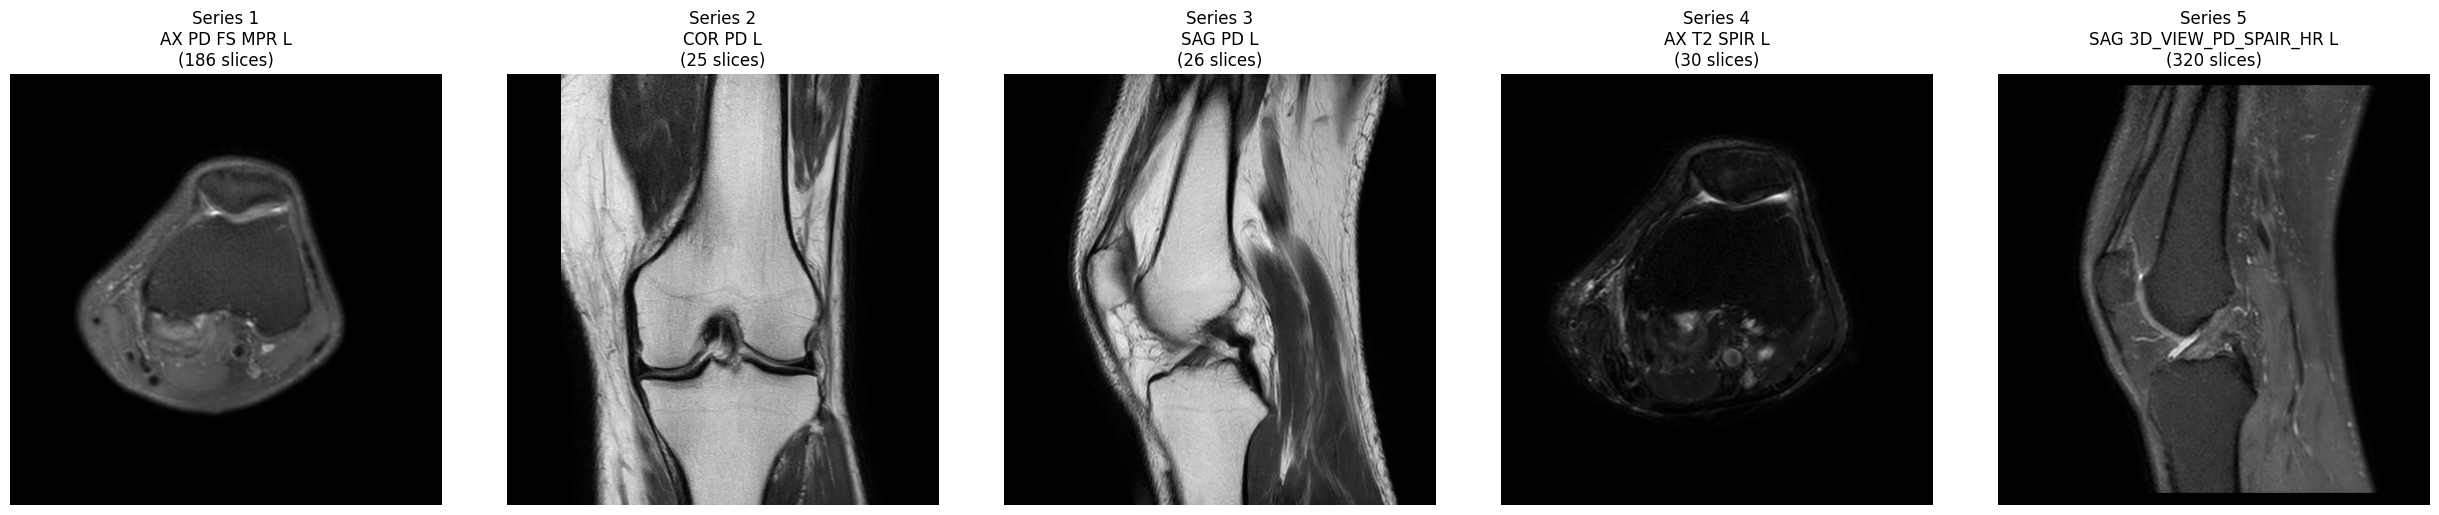

In [2]:
# View the middle slice of EVERY series in the same study
fig, axes = plt.subplots(1, len(series_folders), figsize=(5 * len(series_folders), 5))

for i, s_folder in enumerate(series_folders):
    images, header = load_series(s_folder)
    mid_slice = images[len(images) // 2]  # Pick middle slice

    ax = axes[i] if len(series_folders) > 1 else axes
    ax.imshow(mid_slice, cmap="gray")

    # Extract series description if available in the DICOM header
    series_desc = getattr(header, "SeriesDescription", "Unknown Plane")
    ax.set_title(f"Series {i+1}\n{series_desc}\n({len(images)} slices)")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [3]:
import pandas as pd

TARGETS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA",
           "PF OA", "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]

# Point this at wherever you uploaded train_labels_final.csv as a Kaggle Dataset
df = pd.read_csv("/kaggle/input/datasets/sohailaabdelmageed/final-lables/train_labels_final.csv")

# train_labels_final.csv has no __conf columns (unlike the old train_labels_full.csv) --
# add a constant confidence of 1.0 for every target so KneeMRIDataset's sample-weighting
# still works unchanged. Gold rows still get their extra 3x boost from is_gold inside the Dataset class.
for t in TARGETS:
    conf_col = f"{t}__conf"
    if conf_col not in df.columns:
        df[conf_col] = 1.0

# Drop any leftover diagnostic columns if present (harmless if none exist)
cols_to_drop = [c for c in df.columns if c.endswith("__npos") or c.endswith("__nneg")]
if cols_to_drop:
    df = df.drop(columns=cols_to_drop)

df.to_csv("/kaggle/working/train_labels_clean.csv", index=False)
print(f"Clean shape: {df.shape}")
print(f"is_gold counts:\n{df['is_gold'].value_counts()}")


Clean shape: (4407, 26)
is_gold counts:
is_gold
False    4349
True       58
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import StratifiedGroupKFold

SERIES_META_PATH = "/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series.csv"

target_cols = [c for c in df.columns if c not in ["StudyInstanceUID", "is_gold"] and not c.endswith("__conf")]
conf_cols = [f"{c}__conf" for c in target_cols]

print(f"Target findings ({len(target_cols)}): {target_cols}")

# Stratified Group K-Fold split
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
df["fold"] = -1

# We stratify on `is_gold` so every fold gets ~11-12 real radiologist annotated studies
for fold, (train_idx, val_idx) in enumerate(sgkf.split(df, y=df["is_gold"], groups=df["StudyInstanceUID"])):
    df.loc[val_idx, "fold"] = fold

# Save with folds column added
df.to_csv("/kaggle/working/train_labels_folds.csv", index=False)
print("Fold counts for is_gold == True:\n", df[df['is_gold'] == True]['fold'].value_counts())

df_folds = pd.read_csv("/kaggle/working/train_labels_folds.csv")


Target findings (12): ['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']
Fold counts for is_gold == True:
 fold
1    14
2    14
4    13
0    10
3     7
Name: count, dtype: int64


In [5]:
import torch
from torch.utils.data import Dataset, DataLoader
import cv2
import pydicom
import pathlib
import random

class KneeMRIDataset(Dataset):
    PLANE_PRIORITY = {"Sagittal": 3, "Coronal": 2, "Axial": 1}

    def __init__(self, df, series_dir, series_meta_path=None, num_slices=16, img_size=(224, 224),
                 transform=None, cache_dir=None, augment=False, max_series=3):
        self.df = df.reset_index(drop=True)
        self.series_dir = pathlib.Path(series_dir)
        self.num_slices = num_slices
        self.img_size = img_size
        self.transform = transform
        self.cache_dir = pathlib.Path(cache_dir) if cache_dir else None
        if self.cache_dir:
            self.cache_dir.mkdir(parents=True, exist_ok=True)
        self.max_series = max_series
        self.augment = augment

        # Series metadata lookup for plane-aware selection
        self.series_lookup = {}
        if series_meta_path:
            smeta = pd.read_csv(series_meta_path)
            for _, r in smeta.iterrows():
                self.series_lookup[str(r["SeriesInstanceUID"])] = {
                    "Fluid_Sensitive": r.get("Fluid_Sensitive", 0) or 0,
                    "Fat_Suppression": r.get("Fat_Suppression", 0) or 0,
                    "Anatomical_Plane": r.get("Anatomical_Plane", ""),
                }

        self.target_cols = [c for c in df.columns if c not in ["StudyInstanceUID", "is_gold", "fold"] and not c.endswith("__conf")]
        self.conf_cols = [f"{c}__conf" for c in self.target_cols]

    def __len__(self):
        return len(self.df)

    # ---- series scoring / selection ----
    def _score_series(self, series_uid):
        meta = self.series_lookup.get(series_uid)
        if meta is None:
            return -1
        fluid = meta["Fluid_Sensitive"]
        fatsup = meta["Fat_Suppression"]
        plane_score = self.PLANE_PRIORITY.get(meta["Anatomical_Plane"], 0)
        return fluid * 10 + fatsup * 5 + plane_score

    def _select_multi_series(self, series_folders):
        # Best-scoring series per plane, ordered Sagittal -> Coronal -> Axial
        best_by_plane = {}
        for f in series_folders:
            meta = self.series_lookup.get(f.name)
            plane = meta["Anatomical_Plane"] if meta else "Unknown"
            score = self._score_series(f.name)
            if plane not in best_by_plane or score > best_by_plane[plane][0]:
                best_by_plane[plane] = (score, f)
        ordered = [best_by_plane[p][1] for p in ["Sagittal", "Coronal", "Axial"] if p in best_by_plane]
        return ordered[:self.max_series]

    # ---- per-series decode (header-first sort, only decode kept slices) ----
    def _load_one_series(self, series_path):
        dcm_files = list(series_path.glob("*.dcm"))
        if not dcm_files:
            return None

        headers = []
        for f in dcm_files:
            try:
                ds = pydicom.dcmread(f, stop_before_pixels=True)
                key = int(getattr(ds, 'InstanceNumber', 0)) if hasattr(ds, 'InstanceNumber') \
                      else float(getattr(ds, 'ImagePositionPatient', [0, 0, 0])[2])
                headers.append((key, f))
            except Exception:
                continue
        if not headers:
            return None

        headers.sort(key=lambda x: x[0])
        sorted_files = [f for _, f in headers]

        n = len(sorted_files)
        indices = np.linspace(0, n - 1, num=self.num_slices, dtype=int)
        chosen_files = [sorted_files[i] for i in indices]

        images = []
        for f in chosen_files:
            try:
                ds = pydicom.dcmread(f)
                images.append(ds.pixel_array.astype(np.float32))
            except Exception:
                images.append(None)

        valid = [im for im in images if im is not None]
        if not valid:
            return None
        fill_shape = valid[0].shape
        images = [im if im is not None else np.zeros(fill_shape, dtype=np.float32) for im in images]
        volume = np.array(images)

        p1, p99 = np.percentile(volume, (1, 99))
        denom = (p99 - p1) if (p99 - p1) > 1e-5 else 1.0
        volume = np.clip(volume, p1, p99)
        volume = (volume - p1) / denom

        return np.array([cv2.resize(img, self.img_size, interpolation=cv2.INTER_AREA) for img in volume], dtype=np.float32)

    # ---- study-level loading across up to max_series planes, with caching ----
    def _load_study_multi_series(self, study_uid):
        if self.cache_dir:
            cache_path = self.cache_dir / f"{study_uid}.npz"
            if cache_path.exists():
                data = np.load(cache_path)
                return data["volume"].astype(np.float32) / 255.0, data["mask"].astype(np.float32)

        stack = np.zeros((self.max_series, self.num_slices, self.img_size[0], self.img_size[1]), dtype=np.float32)
        mask = np.zeros((self.max_series,), dtype=np.float32)

        study_path = self.series_dir / study_uid
        series_folders = [f for f in study_path.iterdir() if f.is_dir()] if study_path.exists() else []
        if series_folders:
            for i, series_path in enumerate(self._select_multi_series(series_folders)):
                vol = self._load_one_series(series_path)
                if vol is not None:
                    stack[i] = vol
                    mask[i] = 1.0

        if self.cache_dir:
            cache_path = self.cache_dir / f"{study_uid}.npz"
            np.savez(cache_path, volume=np.clip(stack * 255, 0, 255).astype(np.uint8), mask=mask)
        return stack, mask

    # ---- medically-safe augmentation: same transform across all slices in a series ----
    # Deliberately NO flips: horizontal flip swaps medial/lateral anatomy (breaks
    # Medial/Lateral Meniscus & OA labels); vertical flip inverts superior/inferior
    # anatomy. Neither is a valid augmentation for a labeled knee MRI.
    def _augment_volume(self, volume):
        S, H, W = volume.shape

        angle = random.uniform(-10, 10)              # small rotation: patient positioning variance
        tx = random.uniform(-0.03, 0.03) * W          # small translation: framing variance
        ty = random.uniform(-0.03, 0.03) * H
        scale = random.uniform(0.95, 1.05)            # slight zoom: FOV variance

        M = cv2.getRotationMatrix2D((W / 2, H / 2), angle, scale)
        M[0, 2] += tx
        M[1, 2] += ty

        brightness = random.uniform(-0.05, 0.05)      # simulates scanner/protocol variance
        contrast = random.uniform(0.9, 1.1)

        out = np.empty_like(volume)
        for i in range(S):
            slc = cv2.warpAffine(volume[i], M, (W, H), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
            out[i] = np.clip(slc * contrast + brightness, 0.0, 1.0)

        if random.random() < 0.3:   # mild noise, only sometimes
            noise = np.random.normal(0, 0.01, out.shape).astype(np.float32)
            out = np.clip(out + noise, 0.0, 1.0)

        return out

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        study_uid = row["StudyInstanceUID"]

        stack, mask = self._load_study_multi_series(study_uid)   # [max_series, num_slices, H, W], [max_series]

        if self.augment:
            for i in range(self.max_series):
                if mask[i] > 0:
                    stack[i] = self._augment_volume(stack[i])

        stack_tensor = torch.from_numpy(stack).unsqueeze(2).repeat(1, 1, 3, 1, 1)  # [S, K, 3, H, W]
        mask_tensor = torch.from_numpy(mask)

        targets = torch.tensor(row[self.target_cols].values.astype(np.float32))
        conf_weights = row[self.conf_cols].values.astype(np.float32)
        if row["is_gold"]:
            conf_weights = conf_weights * 3.0
        weights = torch.tensor(conf_weights)

        return stack_tensor, mask_tensor, targets, weights


In [6]:
# Download the official PyTorch RadImageNet ResNet50 weights (one-time, ~100MB, no GPU needed).
# NOTE: this requires internet access enabled for this Kaggle kernel
# (Settings -> Internet -> On). Competition kernels often have this OFF by default.
import os

RADIMAGENET_LOCAL_PATH = "/kaggle/input/datasets/sohailaabdelmageed/model-rad/ResNet50.pt"

if not os.path.exists(RADIMAGENET_LOCAL_PATH):
    os.system("pip install gdown -q")
    exit_code = os.system(f"gdown --id 1RHt2GnuOYlc_gcoTETtBDSW73mFyRAtR -O {RADIMAGENET_LOCAL_PATH}")
    if exit_code != 0 or not os.path.exists(RADIMAGENET_LOCAL_PATH):
        print("[warning] Download failed (check internet access is enabled for this kernel). "
              "Model cell below will automatically fall back to ImageNet weights instead.")
        RADIMAGENET_LOCAL_PATH = None
else:
    print("Already downloaded.")

if RADIMAGENET_LOCAL_PATH:
    size_mb = os.path.getsize(RADIMAGENET_LOCAL_PATH) / 1e6
    print(f"RadImageNet weights ready at {RADIMAGENET_LOCAL_PATH} ({size_mb:.1f} MB)")


Already downloaded.
RadImageNet weights ready at /kaggle/input/datasets/sohailaabdelmageed/model-rad/ResNet50.pt (94.3 MB)


In [7]:
import torch
import torch.nn as nn
import torchvision.models as models


class AttentionPool(nn.Module):
    """Learnable attention pooling over a set of N feature vectors, mask-aware."""
    def __init__(self, feat_dim, hidden_dim=128):
        super().__init__()
        self.attn = nn.Sequential(nn.Linear(feat_dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, 1))

    def forward(self, x, mask=None):
        # x: [B, N, D]; mask: [B, N] where 1 = real, 0 = padding
        scores = self.attn(x).squeeze(-1)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))
        weights = torch.softmax(scores, dim=1)
        return torch.sum(x * weights.unsqueeze(-1), dim=1)


def build_resnet50_backbone(pretrained=True, radimagenet_path=None):
    """Returns a ResNet50 feature extractor (no final fc). Prefers RadImageNet weights
    (domain-matched to radiology, incl. their own ACL/meniscus MR benchmark) over
    generic ImageNet weights when available; falls back gracefully if loading fails."""
    resnet = models.resnet50(weights=None)
    source = "random init"

    if radimagenet_path:
        try:
            state_dict = torch.load(radimagenet_path, map_location="cpu")
            missing, unexpected = resnet.load_state_dict(state_dict, strict=False)
            print(f"RadImageNet load: {len(missing)} missing keys, {len(unexpected)} unexpected keys")
            if len(missing) > 20:  # most keys should match a standard resnet50 -- large mismatch means something's wrong
                raise RuntimeError(f"Too many unmatched keys ({len(missing)}), likely a real mismatch")
            source = f"RadImageNet ({radimagenet_path})"
        except Exception as e:
            print(f"[warning] RadImageNet load failed: {e}")
            print("[warning] Falling back to standard ImageNet pretraining instead.")
            resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
            source = "ImageNet (fallback)"
    elif pretrained:
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        source = "ImageNet"

    print(f"Backbone weights source: {source}")
    return nn.Sequential(*list(resnet.children())[:-1])  # [B*S*K, 2048, 1, 1]


class KneeAbnormalityModelMIL(nn.Module):
    """
    Two-stage attention MIL, ResNet50 backbone (2048-dim features):
      slices  -> (attention pool) -> per-series embedding
      series  -> (attention pool, mask-aware) -> study embedding -> 12 sigmoid heads
    """
    def __init__(self, num_classes=12, pretrained=True, radimagenet_path=RADIMAGENET_LOCAL_PATH):
        super().__init__()
        self.backbone = build_resnet50_backbone(pretrained=pretrained, radimagenet_path=radimagenet_path)
        self.slice_pool = AttentionPool(2048)
        self.series_pool = AttentionPool(2048)
        self.dropout = nn.Dropout(p=0.4)
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x, series_mask):
        # x: [B, S, K, C, H, W]  (S = max_series, K = num_slices)
        b, s, k, c, h, w = x.shape
        x = x.view(b * s * k, c, h, w)
        features = self.backbone(x).view(b, s, k, 2048)

        series_embeds = self.slice_pool(features.view(b * s, k, 2048)).view(b, s, 2048)
        study_embed = self.series_pool(series_embeds, mask=series_mask)

        study_embed = self.dropout(study_embed)
        return self.fc(study_embed)


In [8]:
import time
import torch.nn as nn
from sklearn.metrics import roc_auc_score

criterion = nn.BCEWithLogitsLoss(reduction='none')


scaler = torch.cuda.amp.GradScaler()

def train_one_epoch(model, dataloader, optimizer, criterion, device, print_every=20):
    model.train()
    running_loss = 0.0
    n_batches = len(dataloader)
    epoch_start = time.time()

    for batch_idx, (volumes, series_mask, targets, weights) in enumerate(dataloader, start=1):
        volumes = volumes.to(device)
        series_mask = series_mask.to(device)
        targets = targets.to(device)
        weights = weights.to(device)

        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            logits = model(volumes, series_mask)
            loss_unweighted = criterion(logits, targets)
            loss = (loss_unweighted * weights).mean()

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * volumes.size(0)

        if batch_idx % print_every == 0 or batch_idx == 1 or batch_idx == n_batches:
            elapsed = time.time() - epoch_start
            avg_loss_so_far = running_loss / (batch_idx * dataloader.batch_size)
            eta = (elapsed / batch_idx) * (n_batches - batch_idx)
            print(f"  batch {batch_idx:>4}/{n_batches} | loss {loss.item():.4f} | "
                  f"running_avg {avg_loss_so_far:.4f} | elapsed {elapsed:.0f}s | ETA {eta:.0f}s")

    return running_loss / len(dataloader.dataset)


@torch.no_grad()
def evaluate(model, dataloader, device, print_every=20, verbose=True):
    model.eval()
    all_preds, all_targets = [], []
    n_batches = len(dataloader)
    eval_start = time.time()

    for batch_idx, (volumes, series_mask, targets, _) in enumerate(dataloader, start=1):
        volumes = volumes.to(device)
        series_mask = series_mask.to(device)
        with torch.cuda.amp.autocast():
            logits = model(volumes, series_mask)
        probs = torch.sigmoid(logits)

        all_preds.append(probs.cpu().numpy())
        all_targets.append(targets.numpy())

        if verbose and (batch_idx % print_every == 0 or batch_idx == n_batches):
            elapsed = time.time() - eval_start
            print(f"  [val] batch {batch_idx:>4}/{n_batches} | elapsed {elapsed:.0f}s")

    all_preds = np.vstack(all_preds)
    all_targets = np.vstack(all_targets)

    auc_scores = []
    target_names = dataloader.dataset.target_cols
    for i in range(12):
        binary_target = (all_targets[:, i] > 0.3).astype(int)
        if len(np.unique(binary_target)) > 1:
            auc = roc_auc_score(binary_target, all_preds[:, i])
            auc_scores.append(auc)
            if verbose:
                print(f"    {target_names[i]:<20} AUC: {auc:.4f}")
        elif verbose:
            print(f"    {target_names[i]:<20} AUC: n/a (only one class present in val fold)")

    macro_auc = np.mean(auc_scores) if auc_scores else 0.5
    return macro_auc


/tmp/ipykernel_192/3519577269.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on device: {device}")

# No warm-start this run: the backbone changed from ResNet18 -> ResNet50, so the old
# single-series checkpoint's weights don't match this architecture's shapes at all.
# Training from scratch (RadImageNet or ImageNet weights, set inside the model class).
SINGLE_SERIES_CHECKPOINT = None

BATCH_SIZE = 2     # ResNet50 has ~2.5x the params of ResNet18 -- watch for CUDA OOM, drop to 2-3 if needed
MAX_EPOCHS = 10
EARLY_STOP_PATIENCE = 4
CACHE_DIR = "/kaggle/working/volume_cache_v3"   # images unchanged, safe to reuse this cache

fold_results = {}

for fold_id in range(5):
    print(f"\n{'='*20} FOLD {fold_id} {'='*20}")
    torch.cuda.empty_cache()
    train_df = df_folds[df_folds["fold"] != fold_id].copy()
    val_df   = df_folds[df_folds["fold"] == fold_id].copy()
    print(f"Train studies: {len(train_df)} | Val studies: {len(val_df)}")

    train_dataset = KneeMRIDataset(train_df, TRAIN_SERIES_DIR, series_meta_path=SERIES_META_PATH,
                                    cache_dir=CACHE_DIR, augment=True, max_series=3)
    val_dataset   = KneeMRIDataset(val_df, TRAIN_SERIES_DIR, series_meta_path=SERIES_META_PATH,
                                    cache_dir=CACHE_DIR, augment=False, max_series=3)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    print(f"Train batches/epoch: {len(train_loader)} | Val batches: {len(val_loader)}")

    model = KneeAbnormalityModelMIL(num_classes=12, pretrained=True, radimagenet_path=RADIMAGENET_LOCAL_PATH).to(device)

    if SINGLE_SERIES_CHECKPOINT is not None and fold_id == 0:
        try:
            old_ckpt = torch.load(SINGLE_SERIES_CHECKPOINT, map_location=device, weights_only=False)
            missing, unexpected = model.load_state_dict(old_ckpt["model_state_dict"], strict=False)
            print(f"Warm-started backbone+fc from {SINGLE_SERIES_CHECKPOINT} "
                  f"(val AUC was {old_ckpt.get('val_auc', 'n/a')}). "
                  f"New/uninitialized params: {len(missing)}.")
        except FileNotFoundError:
            print(f"No checkpoint found at {SINGLE_SERIES_CHECKPOINT}, training backbone from scratch weights only.")

    # Differential LR still applies even without warm-start -- keeps the (now ImageNet/RadImageNet,
    # not fine-tuned) backbone moving a bit slower than the brand-new attention/fc layers.
    optimizer = torch.optim.AdamW([
        {"params": model.backbone.parameters(), "lr": 5e-5},      # slightly higher than before since no warm-start head start
        {"params": model.slice_pool.parameters(), "lr": 1e-3},
        {"params": model.series_pool.parameters(), "lr": 1e-3},
        {"params": model.fc.parameters(), "lr": 5e-4},
    ], weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

    best_val_auc = 0.0
    epochs_without_improvement = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        print(f"\n--- Fold {fold_id} | Epoch {epoch:02d} ---")
        epoch_start = time.time()

        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_auc = evaluate(model, val_loader, device, verbose=(epoch == 1))
        scheduler.step(val_auc)

        lrs = [f"{g['lr']:.1e}" for g in optimizer.param_groups]
        print(f"Fold {fold_id} Epoch {epoch:02d} done in {time.time()-epoch_start:.0f}s | "
              f"Train Loss: {train_loss:.4f} | Val Macro AUC: {val_auc:.4f} | "
              f"LRs (backbone/slice/series/fc): {lrs}")

        torch.save({"fold": fold_id, "epoch": epoch, "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(), "val_auc": val_auc,
                    "target_cols": train_dataset.target_cols},
                   f"/kaggle/working/knee_model_mil_v3_fold{fold_id}_last.pt")

        if val_auc > best_val_auc:
            best_val_auc = val_auc
            epochs_without_improvement = 0
            torch.save({"fold": fold_id, "epoch": epoch, "model_state_dict": model.state_dict(),
                        "val_auc": val_auc, "target_cols": train_dataset.target_cols},
                       f"/kaggle/working/knee_model_mil_v3_fold{fold_id}_best.pt")
            print(f"  -> new best model saved for fold {fold_id} (Val Macro AUC: {val_auc:.4f})")
        else:
            epochs_without_improvement += 1
            print(f"  -> no improvement ({epochs_without_improvement}/{EARLY_STOP_PATIENCE})")
            if epochs_without_improvement >= EARLY_STOP_PATIENCE:
                print(f"Early stopping fold {fold_id} at epoch {epoch}. Best Val Macro AUC: {best_val_auc:.4f}")
                break

    fold_results[fold_id] = best_val_auc

print("\n" + "="*50)
print("All folds:", fold_results)
print("Mean CV AUC:", np.mean(list(fold_results.values())))
print("Std  CV AUC:", np.std(list(fold_results.values())))


Training on device: cuda

==================== FOLD 0 ====================
Train studies: 3525 | Val studies: 882
Train batches/epoch: 1763 | Val batches: 441
RadImageNet load: 267 missing keys, 318 unexpected keys
[warning] RadImageNet load failed: Too many unmatched keys (267), likely a real mismatch
[warning] Falling back to standard ImageNet pretraining instead.
Backbone weights source: ImageNet (fallback)

--- Fold 0 | Epoch 01 ---


/tmp/ipykernel_192/3519577269.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  batch    1/1763 | loss 0.6993 | running_avg 0.6993 | elapsed 4s | ETA 6902s
  batch   20/1763 | loss 1.2541 | running_avg 0.6999 | elapsed 31s | ETA 2702s
  batch   40/1763 | loss 0.6314 | running_avg 0.6763 | elapsed 61s | ETA 2632s
  batch   60/1763 | loss 0.5516 | running_avg 0.6809 | elapsed 89s | ETA 2537s
  batch   80/1763 | loss 0.7626 | running_avg 0.6670 | elapsed 117s | ETA 2451s
  batch  100/1763 | loss 0.6422 | running_avg 0.6662 | elapsed 142s | ETA 2357s
  batch  120/1763 | loss 0.5899 | running_avg 0.6654 | elapsed 171s | ETA 2345s
  batch  140/1763 | loss 0.5231 | running_avg 0.6577 | elapsed 201s | ETA 2334s
  batch  160/1763 | loss 0.5266 | running_avg 0.6507 | elapsed 232s | ETA 2324s
  batch  180/1763 | loss 0.5693 | running_avg 0.6452 | elapsed 265s | ETA 2334s
  batch  200/1763 | loss 0.6680 | running_avg 0.6379 | elapsed 290s | ETA 2264s
  batch  220/1763 | loss 0.5500 | running_avg 0.6342 | elapsed 318s | ETA 2229s
  batch  240/1763 | loss 0.6246 | running_avg

/tmp/ipykernel_192/3519577269.py:53: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  [val] batch   20/441 | elapsed 33s
  [val] batch   40/441 | elapsed 61s
  [val] batch   60/441 | elapsed 86s
  [val] batch   80/441 | elapsed 114s
  [val] batch  100/441 | elapsed 147s
  [val] batch  120/441 | elapsed 176s
  [val] batch  140/441 | elapsed 204s
  [val] batch  160/441 | elapsed 232s
  [val] batch  180/441 | elapsed 257s
  [val] batch  200/441 | elapsed 289s
  [val] batch  220/441 | elapsed 327s
  [val] batch  240/441 | elapsed 352s
  [val] batch  260/441 | elapsed 380s
  [val] batch  280/441 | elapsed 406s
  [val] batch  300/441 | elapsed 434s
  [val] batch  320/441 | elapsed 460s
  [val] batch  340/441 | elapsed 487s
  [val] batch  360/441 | elapsed 515s
  [val] batch  380/441 | elapsed 544s
  [val] batch  400/441 | elapsed 575s
  [val] batch  420/441 | elapsed 603s
  [val] batch  440/441 | elapsed 639s
  [val] batch  441/441 | elapsed 640s
    ACL                  AUC: 0.6773
    MCL                  AUC: 0.6764
    Medial Meniscus      AUC: 0.7259
    Lateral Menisc

...

/tmp/ipykernel_192/3519577269.py:53: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  [val] batch   20/441 | elapsed 3s
  [val] batch   40/441 | elapsed 6s
  [val] batch   60/441 | elapsed 9s
  [val] batch   80/441 | elapsed 12s
  [val] batch  100/441 | elapsed 15s
  [val] batch  120/441 | elapsed 18s
  [val] batch  140/441 | elapsed 21s
  [val] batch  160/441 | elapsed 25s
  [val] batch  180/441 | elapsed 28s
  [val] batch  200/441 | elapsed 31s
  [val] batch  220/441 | elapsed 34s
  [val] batch  240/441 | elapsed 37s
  [val] batch  260/441 | elapsed 40s
  [val] batch  280/441 | elapsed 43s
  [val] batch  300/441 | elapsed 46s
  [val] batch  320/441 | elapsed 49s
  [val] batch  340/441 | elapsed 52s
  [val] batch  360/441 | elapsed 55s
  [val] batch  380/441 | elapsed 58s
  [val] batch  400/441 | elapsed 61s
  [val] batch  420/441 | elapsed 64s
  [val] batch  440/441 | elapsed 67s
  [val] batch  441/441 | elapsed 67s
    ACL                  AUC: 0.6730
    MCL                  AUC: 0.7176
    Medial Meniscus      AUC: 0.7544
    Lateral Meniscus     AUC: 0.7377
    

/tmp/ipykernel_192/3519577269.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  batch    1/1763 | loss 0.7050 | running_avg 0.7050 | elapsed 1s | ETA 1345s


KeyboardInterrupt: 

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Rebuild fold 0's val set
val_df = df_folds[df_folds["fold"] == 0].copy()

gold_rows = val_df[val_df["is_gold"] == True]
weak_sample = val_df[val_df["is_gold"] == False].sample(150, random_state=42)
val_df = pd.concat([gold_rows, weak_sample])

val_dataset = KneeMRIDataset(val_df, TRAIN_SERIES_DIR, series_meta_path=SERIES_META_PATH,
                              cache_dir="/kaggle/working/volume_cache_v3", augment=False, max_series=3)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2)

# Update this path once fold 0 of the new ResNet50 run has produced its best checkpoint
ckpt = torch.load("/kaggle/working/knee_model_mil_v3_fold0_best.pt", map_location=device, weights_only=False)
model = KneeAbnormalityModelMIL(num_classes=12, pretrained=False, radimagenet_path=None).to(device)
model.load_state_dict(ckpt["model_state_dict"])
print(f"Loaded fold 0 best checkpoint (epoch {ckpt['epoch']}, val AUC {ckpt['val_auc']:.4f})")

@torch.no_grad()
def evaluate_split_by_gold(model, dataloader, device):
    model.eval()
    all_preds, all_targets = [], []
    for volumes, series_mask, targets, _ in dataloader:
        volumes, series_mask = volumes.to(device), series_mask.to(device)
        probs = torch.sigmoid(model(volumes, series_mask))
        all_preds.append(probs.cpu().numpy())
        all_targets.append(targets.numpy())
    all_preds = np.vstack(all_preds)
    all_targets = np.vstack(all_targets)
    is_gold = dataloader.dataset.df["is_gold"].values.astype(bool)
    for label, mask in [("GOLD-ONLY", is_gold), ("WEAK-LABEL-ONLY", ~is_gold)]:
        aucs = []
        for i in range(12):
            bt = (all_targets[mask, i] > 0.3).astype(int)
            if len(np.unique(bt)) > 1:
                aucs.append(roc_auc_score(bt, all_preds[mask, i]))
        n = mask.sum()
        print(f"{label} (n={n}): macro AUC = {np.mean(aucs):.4f}" if aucs else f"{label} (n={n}): not enough class variety")

evaluate_split_by_gold(model, val_loader, device)


PART 1 — TRAINING CURVES
  saved -> /kaggle/working/figures/01_train_loss.png


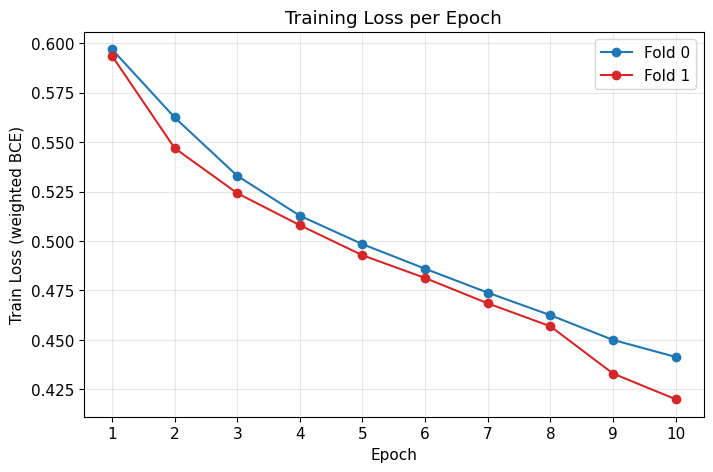

  saved -> /kaggle/working/figures/02_val_auc.png


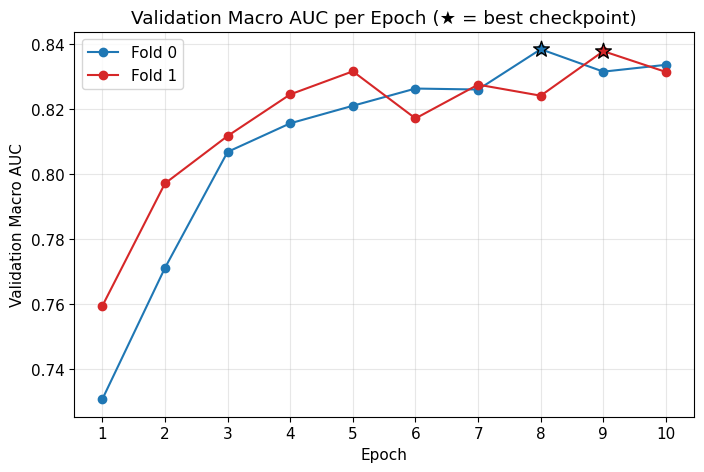

  saved -> /kaggle/working/figures/03_train_vs_val_dual_axis.png


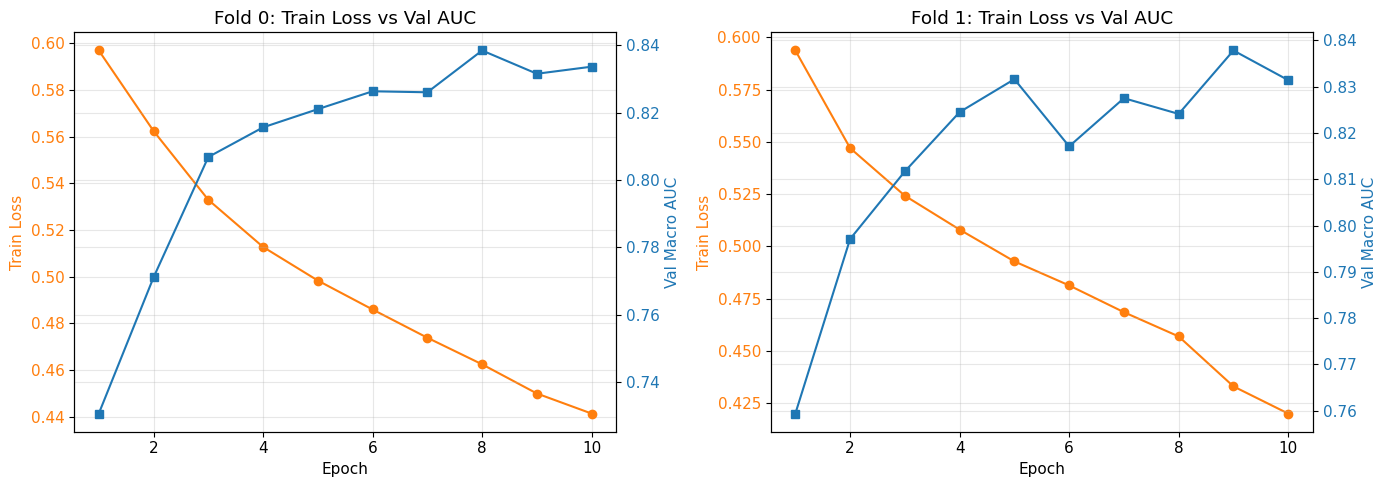

  saved -> /kaggle/working/figures/04_lr_schedule.png


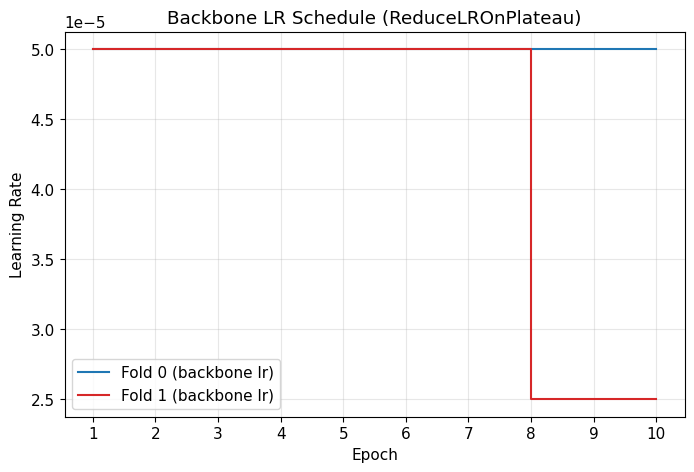

PART 2 — FOLD COMPARISON
  saved -> /kaggle/working/figures/05_fold_comparison.png


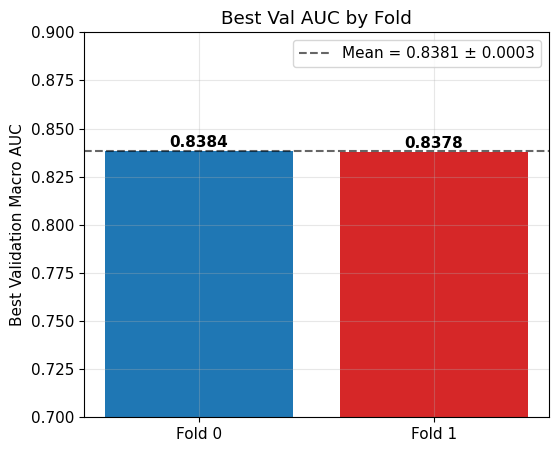

PART 3 — PER-CLASS AUC (epoch 1 snapshot, both folds)
  saved -> /kaggle/working/figures/06_per_class_auc_epoch1.png


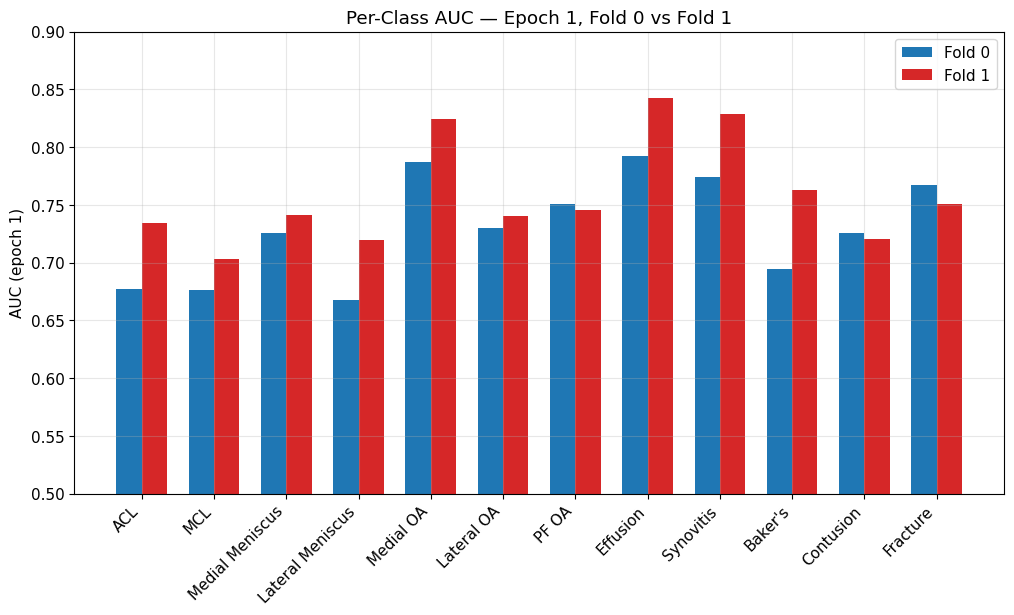

PART 4 — ROC CURVES FROM BEST CHECKPOINTS (live recompute)
Backbone weights source: random init
  saved -> /kaggle/working/figures/07_roc_curves_fold0.png


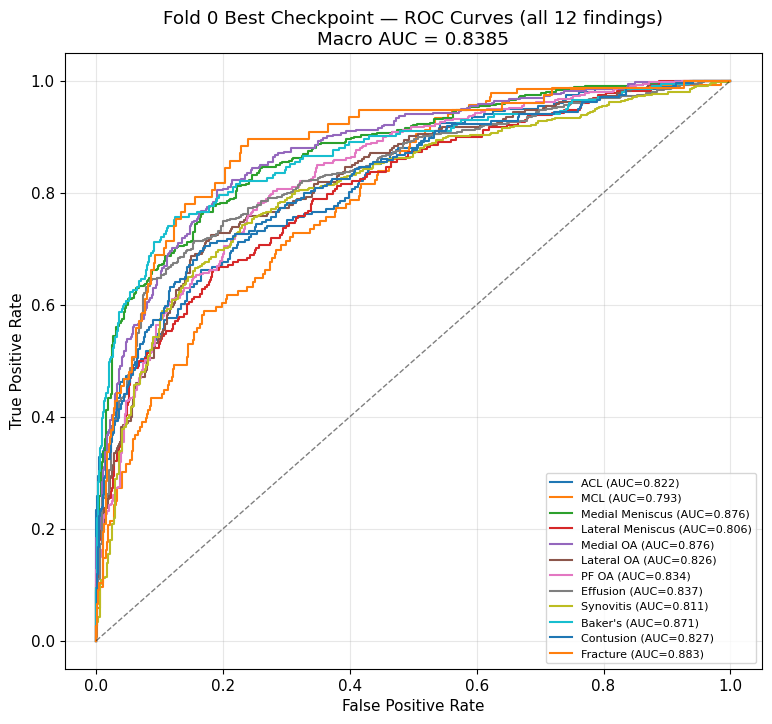

Backbone weights source: random init
  saved -> /kaggle/working/figures/07_roc_curves_fold1.png


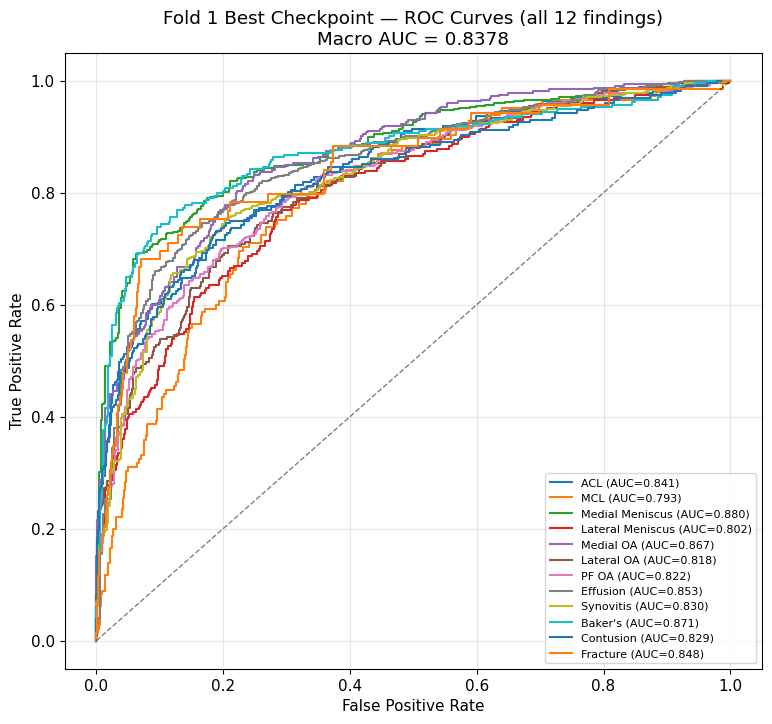

PART 5 — PREPROCESSING FIGURES
  saved -> /kaggle/working/figures/08_label_prevalence.png


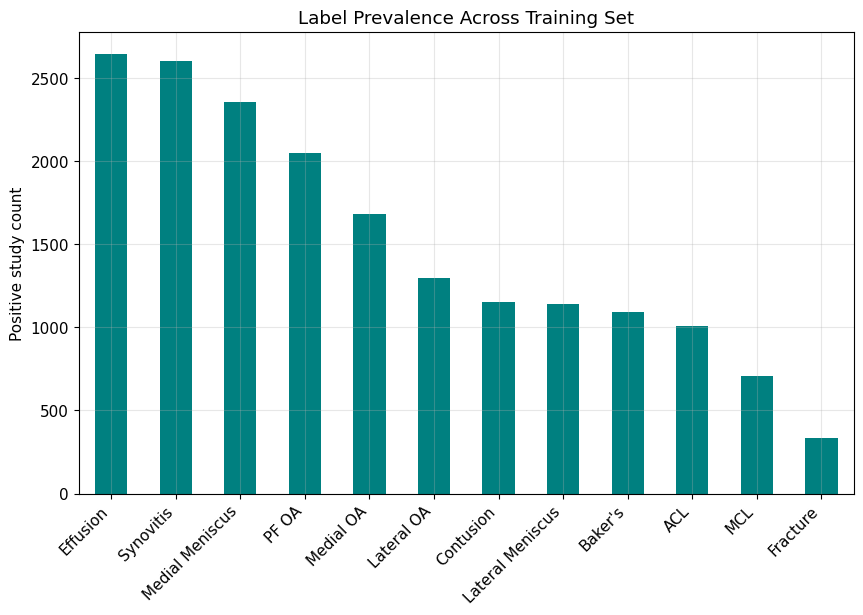

  saved -> /kaggle/working/figures/09_gold_vs_weak.png


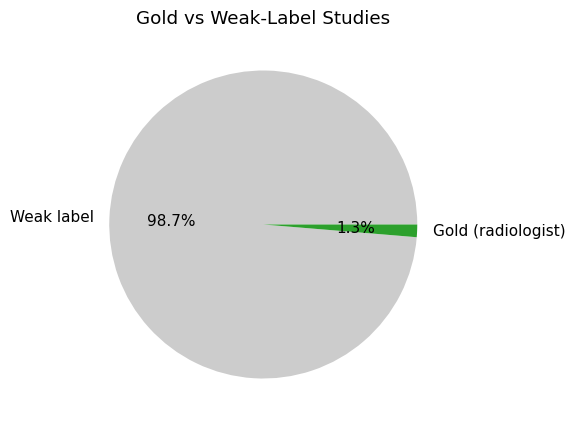

  saved -> /kaggle/working/figures/10_fold_distribution.png


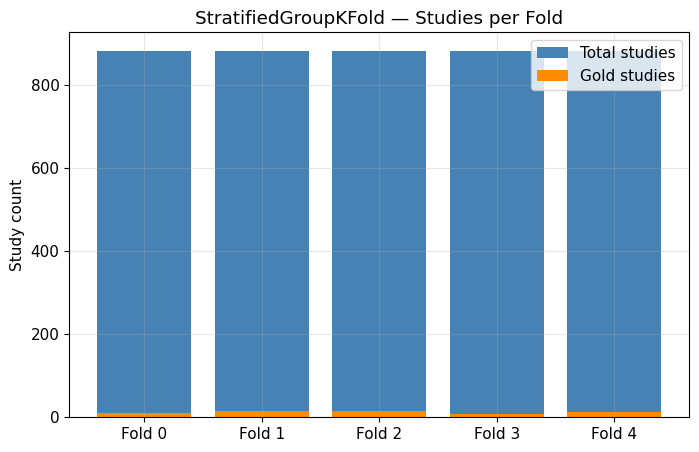

  saved -> /kaggle/working/figures/11_label_correlation_heatmap.png


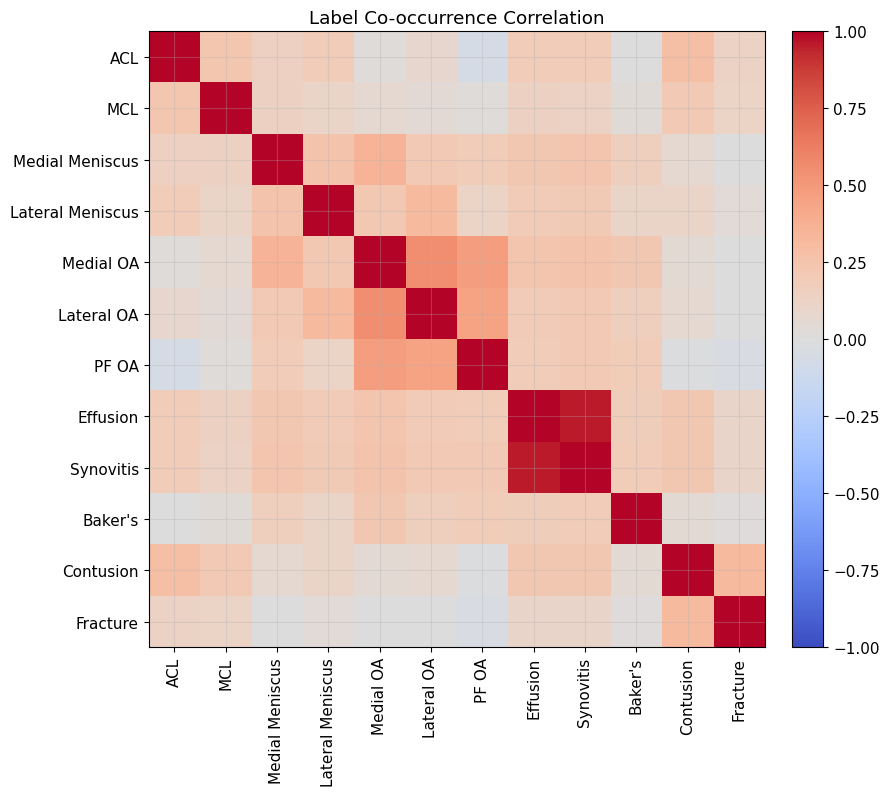


✅ All available figures saved in: /kaggle/working/figures
Files: ['01_train_loss.png', '02_val_auc.png', '03_train_vs_val_dual_axis.png', '04_lr_schedule.png', '05_fold_comparison.png', '06_per_class_auc_epoch1.png', '07_roc_curves_fold0.png', '07_roc_curves_fold1.png', '08_label_prevalence.png', '09_gold_vs_weak.png', '10_fold_distribution.png', '11_label_correlation_heatmap.png']


In [10]:
# ============================================================
# 📊 RESULTS + PREPROCESSING REPORT  (folds 0 & 1 only)
# Saves every figure as PNG to /kaggle/working/figures/
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc as sk_auc, roc_auc_score

FIG_DIR = "/kaggle/working/figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
})

def savefig(name):
    path = os.path.join(FIG_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"  saved -> {path}")
    plt.show()
    plt.close()

# ------------------------------------------------------------
# 0) Ground-truth epoch history, parsed from your actual
#    training log (fold 2 stopped mid epoch-1 -> excluded)
# ------------------------------------------------------------
history = {
    0: {
        "train_loss": [0.5970,0.5625,0.5330,0.5128,0.4984,0.4860,0.4739,0.4625,0.4500,0.4414],
        "val_auc":    [0.7307,0.7711,0.8068,0.8156,0.8210,0.8263,0.8260,0.8384,0.8315,0.8336],
        "lr_backbone":[5e-5]*10,
        "best_epoch": 8, "best_auc": 0.8384,
    },
    1: {
        "train_loss": [0.5937,0.5470,0.5242,0.5080,0.4928,0.4813,0.4685,0.4569,0.4330,0.4200],
        "val_auc":    [0.7594,0.7971,0.8117,0.8245,0.8316,0.8171,0.8275,0.8241,0.8378,0.8314],
        "lr_backbone":[5e-5]*7 + [2.5e-5]*3,   # ReduceLROnPlateau fired after epoch 7
        "best_epoch": 9, "best_auc": 0.8378,
    },
}

epoch1_per_class_auc = {
    0: {"ACL":0.6773,"MCL":0.6764,"Medial Meniscus":0.7259,"Lateral Meniscus":0.6675,
        "Medial OA":0.7869,"Lateral OA":0.7303,"PF OA":0.7507,"Effusion":0.7923,
        "Synovitis":0.7739,"Baker's":0.6940,"Contusion":0.7259,"Fracture":0.7670},
    1: {"ACL":0.7345,"MCL":0.7027,"Medial Meniscus":0.7411,"Lateral Meniscus":0.7196,
        "Medial OA":0.8242,"Lateral OA":0.7403,"PF OA":0.7451,"Effusion":0.8421,
        "Synovitis":0.8283,"Baker's":0.7627,"Contusion":0.7208,"Fracture":0.7511},
}

FOLD_COLORS = {0: "#1f77b4", 1: "#d62728"}

print("="*60)
print("PART 1 — TRAINING CURVES")
print("="*60)

# ---- 1a) Train loss per fold ----
plt.figure(figsize=(8,5))
for fid, h in history.items():
    epochs = range(1, len(h["train_loss"]) + 1)
    plt.plot(epochs, h["train_loss"], marker="o", color=FOLD_COLORS[fid], label=f"Fold {fid}")
plt.xlabel("Epoch"); plt.ylabel("Train Loss (weighted BCE)")
plt.title("Training Loss per Epoch"); plt.legend(); plt.xticks(range(1,11))
savefig("01_train_loss.png")

# ---- 1b) Val AUC per fold ----
plt.figure(figsize=(8,5))
for fid, h in history.items():
    epochs = range(1, len(h["val_auc"]) + 1)
    plt.plot(epochs, h["val_auc"], marker="o", color=FOLD_COLORS[fid], label=f"Fold {fid}")
    best_ep = h["best_epoch"]
    plt.scatter([best_ep], [h["best_auc"]], s=140, marker="*", color=FOLD_COLORS[fid],
                edgecolor="black", zorder=5)
plt.xlabel("Epoch"); plt.ylabel("Validation Macro AUC")
plt.title("Validation Macro AUC per Epoch (★ = best checkpoint)")
plt.legend(); plt.xticks(range(1,11))
savefig("02_val_auc.png")

# ---- 1c) Train loss vs Val AUC, twin-axis, one panel per fold ----
fig, axes = plt.subplots(1, 2, figsize=(14,5))
for ax, fid in zip(axes, history.keys()):
    h = history[fid]
    epochs = range(1, len(h["train_loss"]) + 1)
    ax.plot(epochs, h["train_loss"], color="tab:orange", marker="o", label="Train Loss")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Train Loss", color="tab:orange")
    ax.tick_params(axis="y", labelcolor="tab:orange")
    ax2 = ax.twinx()
    ax2.plot(epochs, h["val_auc"], color="tab:blue", marker="s", label="Val AUC")
    ax2.set_ylabel("Val Macro AUC", color="tab:blue")
    ax2.tick_params(axis="y", labelcolor="tab:blue")
    ax.set_title(f"Fold {fid}: Train Loss vs Val AUC")
plt.tight_layout()
savefig("03_train_vs_val_dual_axis.png")

# ---- 1d) LR schedule ----
plt.figure(figsize=(8,5))
for fid, h in history.items():
    epochs = range(1, len(h["lr_backbone"]) + 1)
    plt.step(epochs, h["lr_backbone"], where="post", color=FOLD_COLORS[fid], label=f"Fold {fid} (backbone lr)")
plt.xlabel("Epoch"); plt.ylabel("Learning Rate")
plt.title("Backbone LR Schedule (ReduceLROnPlateau)")
plt.legend(); plt.xticks(range(1,11))
savefig("04_lr_schedule.png")

print("="*60)
print("PART 2 — FOLD COMPARISON")
print("="*60)

best_aucs = [history[f]["best_auc"] for f in history]
plt.figure(figsize=(6,5))
bars = plt.bar([f"Fold {f}" for f in history], best_aucs, color=[FOLD_COLORS[f] for f in history])
for b, v in zip(bars, best_aucs):
    plt.text(b.get_x()+b.get_width()/2, v+0.002, f"{v:.4f}", ha="center", fontweight="bold")
plt.axhline(np.mean(best_aucs), color="black", linestyle="--", alpha=0.6,
            label=f"Mean = {np.mean(best_aucs):.4f} ± {np.std(best_aucs):.4f}")
plt.ylabel("Best Validation Macro AUC"); plt.ylim(0.7, 0.9)
plt.title("Best Val AUC by Fold"); plt.legend()
savefig("05_fold_comparison.png")

print("="*60)
print("PART 3 — PER-CLASS AUC (epoch 1 snapshot, both folds)")
print("="*60)

targets = list(epoch1_per_class_auc[0].keys())
x = np.arange(len(targets)); width = 0.35
plt.figure(figsize=(12,6))
plt.bar(x - width/2, [epoch1_per_class_auc[0][t] for t in targets], width, label="Fold 0", color=FOLD_COLORS[0])
plt.bar(x + width/2, [epoch1_per_class_auc[1][t] for t in targets], width, label="Fold 1", color=FOLD_COLORS[1])
plt.xticks(x, targets, rotation=45, ha="right")
plt.ylabel("AUC (epoch 1)"); plt.title("Per-Class AUC — Epoch 1, Fold 0 vs Fold 1")
plt.legend(); plt.ylim(0.5, 0.9)
savefig("06_per_class_auc_epoch1.png")

# ------------------------------------------------------------
# PART 4 — LIVE ROC CURVES from saved best checkpoints
# (only runs if the model/dataset classes and files are still
#  available in this kernel session; safely skipped otherwise)
# ------------------------------------------------------------
print("="*60)
print("PART 4 — ROC CURVES FROM BEST CHECKPOINTS (live recompute)")
print("="*60)

try:
    import torch
    for fid in [0, 1]:
        ckpt_path = f"/kaggle/working/knee_model_mil_v3_fold{fid}_best.pt"
        if not os.path.exists(ckpt_path):
            print(f"  [skip] no checkpoint at {ckpt_path}")
            continue

        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        m = KneeAbnormalityModelMIL(num_classes=12, pretrained=False, radimagenet_path=None).to(device)
        m.load_state_dict(ckpt["model_state_dict"])
        m.eval()

        val_df_f = df_folds[df_folds["fold"] == fid].copy()
        val_ds_f = KneeMRIDataset(val_df_f, TRAIN_SERIES_DIR, series_meta_path=SERIES_META_PATH,
                                   cache_dir="/kaggle/working/volume_cache_v3", augment=False, max_series=3)
        val_dl_f = DataLoader(val_ds_f, batch_size=4, shuffle=False, num_workers=2)

        all_preds, all_targets = [], []
        with torch.no_grad():
            for volumes, series_mask, tgt, _ in val_dl_f:
                volumes, series_mask = volumes.to(device), series_mask.to(device)
                probs = torch.sigmoid(m(volumes, series_mask))
                all_preds.append(probs.cpu().numpy())
                all_targets.append(tgt.numpy())
        all_preds = np.vstack(all_preds)
        all_targets = np.vstack(all_targets)
        names = val_ds_f.target_cols

        plt.figure(figsize=(9,8))
        macro_aucs = []
        for i, name in enumerate(names):
            bt = (all_targets[:, i] > 0.3).astype(int)
            if len(np.unique(bt)) < 2:
                continue
            fpr, tpr, _ = roc_curve(bt, all_preds[:, i])
            a = sk_auc(fpr, tpr)
            macro_aucs.append(a)
            plt.plot(fpr, tpr, lw=1.5, label=f"{name} (AUC={a:.3f})")
        plt.plot([0,1],[0,1], "k--", lw=1, alpha=0.5)
        plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
        plt.title(f"Fold {fid} Best Checkpoint — ROC Curves (all 12 findings)\nMacro AUC = {np.mean(macro_aucs):.4f}")
        plt.legend(fontsize=8, loc="lower right", ncol=1)
        savefig(f"07_roc_curves_fold{fid}.png")

except NameError as e:
    print(f"  [skip Part 4] required variable not in memory ({e}). "
          f"Run this cell in the same session right after cell 8/9, or re-load "
          f"device/model/dataset classes first.")
except Exception as e:
    print(f"  [skip Part 4] {e}")

# ------------------------------------------------------------
# PART 5 — PREPROCESSING / EDA FIGURES (for the presentation)
# ------------------------------------------------------------
print("="*60)
print("PART 5 — PREPROCESSING FIGURES")
print("="*60)

try:
    target_cols_eda = [c for c in df_folds.columns
                        if c not in ["StudyInstanceUID", "is_gold", "fold"] and not c.endswith("__conf")]

    # 5a) Label prevalence
    prevalence = (df_folds[target_cols_eda] > 0.3).sum().sort_values(ascending=False)
    plt.figure(figsize=(10,6))
    prevalence.plot(kind="bar", color="teal")
    plt.ylabel("Positive study count"); plt.title("Label Prevalence Across Training Set")
    plt.xticks(rotation=45, ha="right")
    savefig("08_label_prevalence.png")

    # 5b) is_gold distribution
    plt.figure(figsize=(5,5))
    df_folds["is_gold"].value_counts().plot(
        kind="pie", autopct="%1.1f%%", labels=["Weak label","Gold (radiologist)"],
        colors=["#cccccc", "#2ca02c"])
    plt.ylabel(""); plt.title("Gold vs Weak-Label Studies")
    savefig("09_gold_vs_weak.png")

    # 5c) Fold size / balance
    plt.figure(figsize=(8,5))
    fold_counts = df_folds["fold"].value_counts().sort_index()
    fold_gold_counts = df_folds[df_folds["is_gold"]]["fold"].value_counts().sort_index()
    x = np.arange(len(fold_counts))
    plt.bar(x, fold_counts.values, color="steelblue", label="Total studies")
    plt.bar(x, fold_gold_counts.reindex(fold_counts.index, fill_value=0).values,
            color="darkorange", label="Gold studies")
    plt.xticks(x, [f"Fold {i}" for i in fold_counts.index])
    plt.ylabel("Study count"); plt.title("StratifiedGroupKFold — Studies per Fold")
    plt.legend()
    savefig("10_fold_distribution.png")

    # 5d) Label co-occurrence heatmap
    plt.figure(figsize=(9,8))
    corr = (df_folds[target_cols_eda] > 0.3).astype(int).corr()
    im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.xticks(range(len(target_cols_eda)), target_cols_eda, rotation=90)
    plt.yticks(range(len(target_cols_eda)), target_cols_eda)
    plt.title("Label Co-occurrence Correlation")
    savefig("11_label_correlation_heatmap.png")

except NameError as e:
    print(f"  [skip Part 5] df_folds not in memory ({e}). Run cell 3 first.")

print("\n✅ All available figures saved in:", FIG_DIR)
print("Files:", sorted(os.listdir(FIG_DIR)))